# Modelo de predicción de no afiliación a salud

En este notebook entrenamos un modelo supervisado que predice si una persona de la encuesta ASP 2022 **no tiene afiliación al sistema de salud**, a partir de sus características sociodemográficas y de la localidad donde vive. Los pasos son:

- Preparar la variable objetivo y las variables de entrada
- Entrenar una regresión logística como línea base
- Entrenar modelos de ensamble (Random Forest y Gradient Boosting)
- Optimizar hiperparámetros con validación cruzada
- Evaluar el mejor modelo con datos que no vio
- Interpretar el modelo con SHAP
- Guardar el modelo para el endpoint de AWS

In [23]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, uniform

In [10]:
#cargamos el dataset limpio (el mismo que usamos para el clustering)
df = pd.read_csv("../data/processed/asp_2022_variables_limpio.csv")
print("Filas y columnas:", df.shape)

df["afiliado_seg_social_salud"].value_counts()

Filas y columnas: (3003, 50)


afiliado_seg_social_salud
Sí                     1499
No                     1492
No sabe/No responde      12
Name: count, dtype: int64

# Variable objetivo

La propuesta planteaba tres clases (afiliado / no afiliado / desconocido), pero "No sabe/No responde" son solo 12 personas (0,4 %): no alcanza para que un modelo aprenda esa clase. Por eso la dejamos **binaria**:

- **1 = NO afiliada** (es lo que queremos detectar)
- **0 = afiliada**

y quitamos las 12 personas sin respuesta. Las clases quedan **balanceadas** (casi 50 % y 50 %), así que no hace falta remuestreo.

In [11]:
#quitamos a quienes no saben o no respondieron
df = df[df["afiliado_seg_social_salud"] != "No sabe/No responde"].reset_index(drop=True)

#variable objetivo: 1 = NO afiliada, 0 = afiliada
y = (df["afiliado_seg_social_salud"] == "No").astype(int)

print("Personas:", len(df))
print("Proporción de NO afiliadas: %0.3f" % y.mean())

Personas: 2991
Proporción de NO afiliadas: 0.499


# Variables de entrada

Usamos **las mismas 18 variables del clustering** con la misma transformación, para que el modelo y los perfiles hablen el mismo idioma. Para no copiar los diccionarios a mano, los leemos del archivo `clustering_config.json` que guardamos en el notebook de minería.

Además agregamos **3 indicadores de la localidad** (de SaluData) que pide la propuesta: pobreza monetaria 2021, coeficiente de Gini 2021 y % de afiliados al régimen subsidiado en 2022.

**Variables que NO entran (fuga de información):** `regimen_salud`, las preguntas de barreras en salud, `atencion_medica_ult_anio` y similares. Solo se les preguntaron a quienes están afiliadas o dependen de estar afiliada: si las usamos, el modelo "haría trampa" con información que ya revela la respuesta.

**Tampoco usamos `cluster` como variable:** se calcula con las mismas 18 variables, así que no aporta información nueva.

In [12]:
#diccionarios de recodificación guardados en el notebook de minería
with open("modelos/clustering_config.json", encoding="utf-8") as archivo:
    config = json.load(archivo)

variables = config["variables"]   #las 18 variables, en el mismo orden del clustering
print(variables)

['edad', 'personas_hogar', 'dependientes_economicos', 'autopercepcion_nivel_economico', 'horas_semana_asp', 'edad_inicio_asp', 'tiempo_viviendo_bogota', 'nivel_educativo', 'tipo_vivienda', 'migrante', 'grupo_etnico', 'victima_conflicto_armado', 'ingresos_insuficientes', 'paga_intermediario_tercero', 'discriminacion_general', 'amenazas_recibidas', 'forzada_relaciones_sexuales', 'violencia_fuerza_publica']


In [13]:
#tomamos las columnas originales del CSV
columnas_originales = ["edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
                       "horas_semana_asp", "edad_inicio_asp", "tiempo_viviendo_bogota", "nivel_educativo",
                       "tipo_vivienda", "pais_nacimiento", "autoreconocimiento_etnico", "victima_conflicto_armado",
                       "ingresos_suficientes_gastos", "paga_intermediario_tercero", "discriminacion_general",
                       "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]
X = df[columnas_originales].copy()

#"No sabe/No responde" -> moda (igual que en minería)
for col in X.columns:
    if X[col].dtype != "int64" and X[col].dtype != "float64":
        moda = X[col][X[col] != "No sabe/No responde"].mode()[0]
        X[col] = X[col].replace("No sabe/No responde", moda)

#ordinales con los diccionarios del JSON
for col, diccionario in config["recodificacion"].items():
    X[col] = X[col].map(diccionario)

#binarias a 1 y 0
X["pais_nacimiento"] = (X["pais_nacimiento"] != "Colombia").astype(int)
X["autoreconocimiento_etnico"] = (X["autoreconocimiento_etnico"] != "Ninguno").astype(int)
X["ingresos_suficientes_gastos"] = (X["ingresos_suficientes_gastos"] == "No").astype(int)
for col in ["victima_conflicto_armado", "paga_intermediario_tercero", "discriminacion_general",
            "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]:
    X[col] = (X[col] == "Sí").astype(int)

X = X.rename(columns={"pais_nacimiento": "migrante",
                      "autoreconocimiento_etnico": "grupo_etnico",
                      "ingresos_suficientes_gastos": "ingresos_insuficientes"})

#comprobamos que quedaron igual que en el clustering
print("Mismas variables y orden que el clustering:", list(X.columns) == variables)

Mismas variables y orden que el clustering: True


In [14]:
#indicadores de la localidad (un valor por localidad) desde la base integrada con SaluData
indicadores = pd.read_csv("../data/processed/asp_2022_saludata_integrado.csv")
indicadores = indicadores[["localidad", "pobreza_monetaria_pct_2021", "gini_2021",
                           "subsidiado_pct_propio_2022"]].drop_duplicates()
print("Localidades con indicadores:", len(indicadores))

#pegamos los indicadores a cada persona según su localidad
X["localidad"] = df["localidad"]
X = X.merge(indicadores, on="localidad", how="left").drop(columns="localidad")

print("Valores vacíos:", X.isnull().sum().sum())
print("Filas y columnas de X:", X.shape)
X.head()

Localidades con indicadores: 19
Valores vacíos: 0
Filas y columnas de X: (2991, 21)


,edad,personas_hogar,dependientes_economicos,autopercepcion_nivel_economico,horas_semana_asp,edad_inicio_asp,tiempo_viviendo_bogota,nivel_educativo,tipo_vivienda,migrante,...,victima_conflicto_armado,ingresos_insuficientes,paga_intermediario_tercero,discriminacion_general,amenazas_recibidas,forzada_relaciones_sexuales,violencia_fuerza_publica,pobreza_monetaria_pct_2021,gini_2021,subsidiado_pct_propio_2022
0,19,1,0,5,48,18,0,4,0,0,...,0,1,1,0,0,0,0,23.94,0.46,14.39
1,26,1,2,4,48,26,1,5,1,1,...,0,1,1,0,0,0,0,23.94,0.46,14.39
2,21,7,4,5,48,21,1,2,0,1,...,0,1,1,0,1,1,1,23.94,0.46,14.39
3,20,2,0,1,42,16,0,3,2,0,...,0,0,0,0,0,0,0,23.94,0.46,14.39
4,20,1,4,1,56,16,0,2,2,1,...,0,1,0,0,0,0,0,23.94,0.46,14.39


# Separación en entrenamiento y prueba

Separamos el **20 % de las personas como conjunto de prueba** y no lo tocamos hasta el final: es como un examen con preguntas que el modelo nunca vio. Con el 80 % restante entrenamos y comparamos modelos usando validación cruzada.

Usamos `stratify=y` para que ambos conjuntos tengan la misma proporción de personas no afiliadas.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)

print("Entrenamiento:", X_train.shape, " Proporción NO afiliadas: %0.3f" % y_train.mean())
print("Prueba:       ", X_test.shape, " Proporción NO afiliadas: %0.3f" % y_test.mean())

Entrenamiento: (2392, 21)  Proporción NO afiliadas: 0.499
Prueba:        (599, 21)  Proporción NO afiliadas: 0.499


# Línea base: regresión logística

La regresión logística estima la **probabilidad de no estar afiliada** combinando las variables con un peso (coeficiente) cada una. Es simple e interpretable, por eso la usamos como punto de comparación.

**Validación cruzada (5 folds):** dividimos el conjunto de entrenamiento en 5 partes; entrenamos con 4 y evaluamos con la que queda, rotando 5 veces. Así cada resultado se mide con datos que el modelo no vio, y el promedio es más confiable que una sola división.

**Métricas** (para la clase 1 = NO afiliada):

- **AUC**: qué tan bien ordena a las personas de mayor a menor riesgo. 0,5 = al azar, 1 = perfecto. Es la métrica principal.
- **Recall**: de todas las personas que **realmente** no están afiliadas, qué porcentaje detecta el modelo.
- **Precisión**: de las personas que el modelo **marca** como no afiliadas, qué porcentaje realmente lo es.
- **F1**: combina recall y precisión en un solo número.
- **Exactitud (accuracy)**: porcentaje total de aciertos. Como las clases están balanceadas sí es interpretable, pero no es la principal.

In [16]:
#validación cruzada estratificada: 5 partes con la misma proporción de no afiliadas
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#métricas que vamos a calcular en cada parte
metricas = ["roc_auc", "f1", "recall", "precision", "accuracy"]

#pipeline: primero escalar, después la regresión logística
modelo_logistico = Pipeline([
    ("escalador", StandardScaler()),
    ("logistica", LogisticRegression(max_iter=1000))
])

In [17]:
#entrenamos y evaluamos 5 veces
resultados_log = cross_validate(modelo_logistico, X_train, y_train,
                                cv=validacion, scoring=metricas)

#tabla con el resultado de cada parte
tabla_log = pd.DataFrame({m: resultados_log["test_" + m] for m in metricas})
tabla_log.index = ["Parte " + str(i + 1) for i in range(5)]

print("Promedio:\n", tabla_log.mean().round(3))
print("\nDesviación estándar:\n", tabla_log.std().round(3))
tabla_log.round(3)

Promedio:
 roc_auc      0.855
f1           0.808
recall       0.757
precision    0.867
accuracy     0.821
dtype: float64

Desviación estándar:
 roc_auc      0.025
f1           0.028
recall       0.034
precision    0.034
accuracy     0.026
dtype: float64


,roc_auc,f1,recall,precision,accuracy
Parte 1,0.864,0.817,0.757,0.887,0.831
Parte 2,0.827,0.772,0.715,0.838,0.789
Parte 3,0.831,0.793,0.765,0.824,0.801
Parte 4,0.885,0.846,0.807,0.889,0.854
Parte 5,0.867,0.812,0.741,0.898,0.828


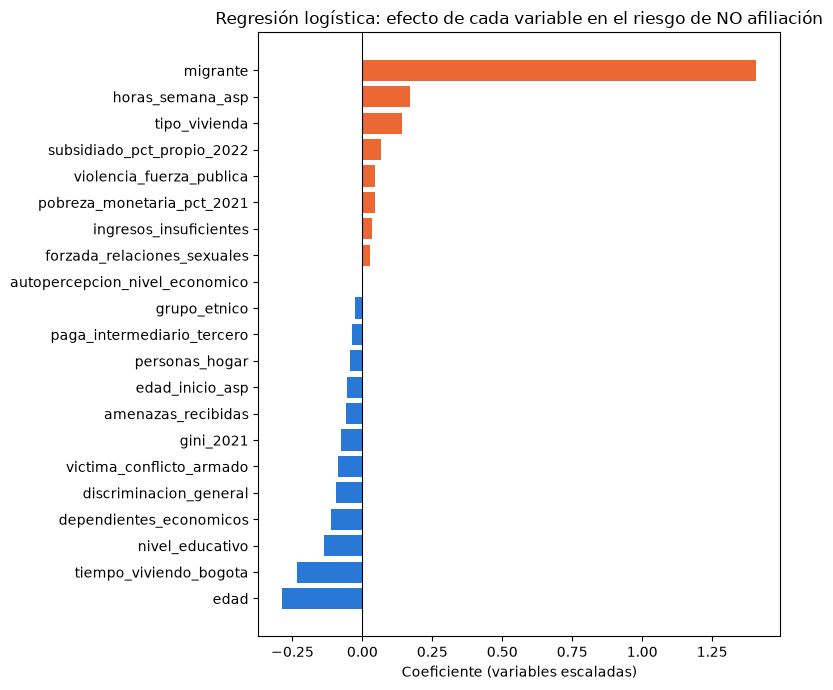

In [18]:
#entrenamos con todo el conjunto de entrenamiento para ver los coeficientes
modelo_logistico.fit(X_train, y_train)

coeficientes = pd.Series(modelo_logistico.named_steps["logistica"].coef_[0],
                         index=X_train.columns).sort_values()

#gráfica: positivo = aumenta el riesgo de NO estar afiliada, negativo = lo disminuye
plt.figure(figsize=(8, 7), dpi=100)
colores_coef = ["#eb6834" if c > 0 else "#2a78d6" for c in coeficientes]
plt.barh(coeficientes.index, coeficientes.values, color=colores_coef)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente (variables escaladas)")
plt.title("Regresión logística: efecto de cada variable en el riesgo de NO afiliación")
plt.tight_layout()
plt.show()

**Resultados de la línea base** (validación cruzada, 5 partes):

- **AUC = 0,855**: el modelo ordena bien a las personas según su riesgo.
- **Precisión = 0,87** y **recall = 0,76**: cuando el modelo marca a alguien como no afiliada casi siempre acierta, pero **deja sin detectar a cerca de 1 de cada 4** personas no afiliadas. Para una herramienta de focalización de política pública, ese recall es lo que más conviene mejorar.

**Coeficientes:** el factor que más pesa, por mucho, es **ser migrante** (coeficiente 1,41, cinco veces más que el siguiente). Le siguen la **edad** y el **tiempo viviendo en Bogotá**: las personas más jóvenes y recién llegadas tienen más riesgo. Los indicadores de localidad tienen coeficientes muy pequeños.

Esto coincide con los perfiles del clustering: el perfil "Migrantes de llegada reciente" es el de menor afiliación.

# Modelos de ensamble

Un **ensamble** combina muchos modelos simples (árboles de decisión) para obtener uno más fuerte. Probamos dos tipos:

- **Random Forest**: entrena cientos de árboles **en paralelo**, cada uno con una muestra al azar de personas y de variables, y al final **vota**. Al promediar muchos árboles distintos se reduce el sobreajuste.
- **Gradient Boosting**: entrena árboles **uno detrás de otro**; cada árbol nuevo se concentra en corregir los errores de los anteriores.

A diferencia de la regresión logística, los árboles **no necesitan escalado** (solo comparan si un valor es mayor o menor que un umbral) y pueden captar **interacciones** entre variables, por ejemplo que el efecto de ser migrante dependa del tiempo en Bogotá.

Por ahora usamos hiperparámetros razonables; en la siguiente sección los optimizamos.

In [20]:
#los tres modelos que vamos a comparar
modelos = {
    "Regresión logística": modelo_logistico,
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [21]:
#evaluamos los tres modelos con la MISMA validación cruzada
resultados = {}
for nombre, modelo in modelos.items():
    resultados[nombre] = cross_validate(modelo, X_train, y_train,
                                        cv=validacion, scoring=metricas)
    print(nombre, "listo")

#tabla comparativa con el promedio de cada métrica
comparacion = pd.DataFrame({nombre: {m: r["test_" + m].mean() for m in metricas}
                            for nombre, r in resultados.items()}).T
comparacion.round(3)

Regresión logística listo
Random Forest listo
Gradient Boosting listo


,roc_auc,f1,recall,precision,accuracy
Regresión logística,0.855,0.808,0.757,0.867,0.821
Random Forest,0.872,0.811,0.762,0.868,0.823
Gradient Boosting,0.861,0.804,0.764,0.851,0.814


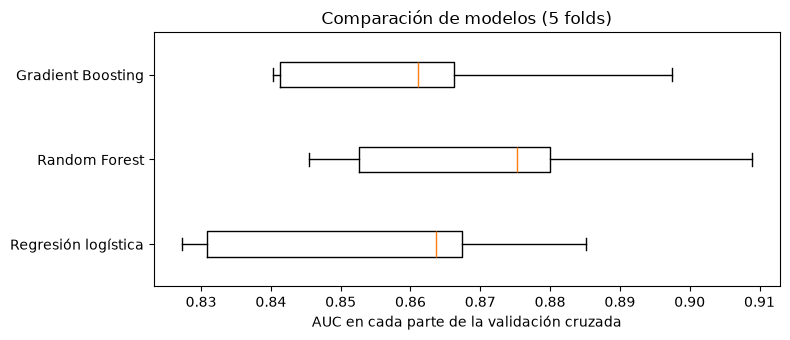

In [22]:
#AUC de cada parte de la validación, por modelo
plt.figure(figsize=(8, 3.5), dpi=100)
plt.boxplot([r["test_roc_auc"] for r in resultados.values()],
            orientation="horizontal", tick_labels=list(resultados.keys()))
plt.xlabel("AUC en cada parte de la validación cruzada")
plt.title("Comparación de modelos (5 folds)")
plt.tight_layout()
plt.show()

**Comparación (validación cruzada, 5 partes):**

- **Random Forest** tiene el mejor AUC (**0,873**), seguido de Gradient Boosting (0,861) y la regresión logística (0,855).
- La mejora sobre la línea base es **pequeña** (+0,018 de AUC) y en F1, recall y precisión los tres modelos quedan casi iguales.
- El **recall sigue cerca de 0,76** en los tres: todos dejan sin detectar a cerca de 1 de cada 4 personas no afiliadas.

Interpretación: la mayor parte de la señal está en pocas variables (sobre todo la condición migratoria), y eso lo capta bien hasta un modelo lineal. Los ensambles agregan un poco al captar interacciones. Pasamos **Random Forest** a la optimización de hiperparámetros por tener el mejor AUC, y también optimizamos Gradient Boosting para confirmar.

# Optimización de hiperparámetros

Los **hiperparámetros** son decisiones que tomamos antes de entrenar (cuántos árboles, qué tan profundos, cuántas personas mínimo por hoja). Para elegirlos probamos varias combinaciones con la misma validación cruzada y nos quedamos con la de mejor AUC. Usamos las dos estrategias de la propuesta:

- **Grid Search** (Random Forest): prueba **todas** las combinaciones de una cuadrícula. Es exhaustivo, pero el número de pruebas crece muy rápido.
- **Random Search** (Gradient Boosting): prueba un número fijo de combinaciones **al azar** dentro de unos rangos. Explora más valores con menos pruebas; conviene cuando hay muchos hiperparámetros.

In [24]:
#cuadrícula de hiperparámetros para Random Forest (4 x 4 x 2 = 32 combinaciones)
grid_rf = {
    "max_depth": [None, 5, 10, 20],        #profundidad máxima de cada árbol (None = sin límite)
    "min_samples_leaf": [1, 5, 10, 20],    #mínimo de personas en cada hoja
    "max_features": ["sqrt", 0.5]          #cuántas variables mira cada división
}

busqueda_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    grid_rf, cv=validacion, scoring="roc_auc", n_jobs=-1)
busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print("Mejor AUC (validación cruzada): %0.3f" % busqueda_rf.best_score_)

Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
Mejor AUC (validación cruzada): 0.872


In [25]:
#las 5 mejores combinaciones
top_rf = pd.DataFrame(busqueda_rf.cv_results_).sort_values("rank_test_score")
top_rf[["params", "mean_test_score", "std_test_score"]].head(5).round(4)

,params,mean_test_score,std_test_score
1,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.8724,0.0224
25,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.8724,0.0224
21,"{'max_depth': 10, 'max_features': 0.5, 'min_sa...",0.8710,0.0199
17,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.8709,0.0223
18,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.8707,0.0242


In [26]:
#rangos de valores para Gradient Boosting (se eligen al azar dentro de ellos)
distribuciones_gb = {
    "n_estimators": randint(100, 500),         #número de árboles: entero entre 100 y 499
    "learning_rate": uniform(0.01, 0.19),      #tasa de aprendizaje: decimal entre 0.01 y 0.20
    "max_depth": [2, 3, 4],                    #profundidad de cada árbol
    "subsample": [0.7, 0.85, 1.0],             #fracción de personas que ve cada árbol
    "min_samples_leaf": [1, 5, 10, 20]
}

busqueda_gb = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    distribuciones_gb, n_iter=30, cv=validacion,
    scoring="roc_auc", random_state=42, n_jobs=-1)
busqueda_gb.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_gb.best_params_)
print("Mejor AUC (validación cruzada): %0.3f" % busqueda_gb.best_score_)

Mejores hiperparámetros: {'learning_rate': np.float64(0.02235980266720311), 'max_depth': 2, 'min_samples_leaf': 20, 'n_estimators': 113, 'subsample': 0.85}
Mejor AUC (validación cruzada): 0.867


In [27]:
#evaluamos los modelos optimizados con todas las métricas, con la misma validación
modelos_optimizados = {
    "Regresión logística": modelo_logistico,
    "Random Forest (optimizado)": busqueda_rf.best_estimator_,
    "Gradient Boosting (optimizado)": busqueda_gb.best_estimator_
}

resultados_opt = {}
for nombre, modelo in modelos_optimizados.items():
    resultados_opt[nombre] = cross_validate(modelo, X_train, y_train,
                                            cv=validacion, scoring=metricas)

comparacion_opt = pd.DataFrame({nombre: {m: r["test_" + m].mean() for m in metricas}
                                for nombre, r in resultados_opt.items()}).T
comparacion_opt.round(3)

,roc_auc,f1,recall,precision,accuracy
Regresión logística,0.855,0.808,0.757,0.867,0.821
Random Forest (optimizado),0.872,0.811,0.762,0.868,0.823
Gradient Boosting (optimizado),0.867,0.806,0.750,0.870,0.819


**Resultados de la optimización:**

- **Random Forest:** la mejor combinación fue `max_depth=None`, `max_features="sqrt"`, `min_samples_leaf=5`, que es **la misma que ya usábamos**. Su AUC sigue en ~0,873. Las 5 mejores combinaciones difieren en menos de 0,002 de AUC, mucho menos que la variación entre partes (~0,02): el modelo es **robusto** a sus hiperparámetros.
- **Gradient Boosting:** mejoró de 0,861 a ~0,867 con árboles poco profundos (`max_depth=2`) y una tasa de aprendizaje baja, pero sigue por debajo de Random Forest.

La optimización casi no mejora los modelos: indica que estamos cerca del **límite de información** que tienen estas 21 variables, no de un problema de ajuste del modelo.

**Modelo elegido: Random Forest optimizado**, por tener el mejor AUC. El recall (~0,76) no cambia con los hiperparámetros porque estos optimizan el AUC; lo mejoraremos ajustando el **umbral de decisión** en la evaluación final.